# Evaluation: Generated DAGs vs Ground-Truth

Compares graphs produced by GDSS (after reverse diffusion) against the held-out test set.
Supports **multiple runs / architectures** — add entries to `EXPERIMENTS` and re-run.

- DAG validity rate
- In-degree / out-degree distributions
- Edge count and density distributions
- Side-by-side visual inspection

**Run from the `gdss/` directory.**

## 0 · Configuration

Edit the two paths below to point at your experiment.

In [45]:
import os, sys
os.chdir(os.path.dirname(os.path.abspath('.')))

DATASET      = 'sem_SF_d20'
TEST_SPLIT   = 0.2
QUANTIZE_THR = 0.5
DATA_PKL     = f'/home/nicolas/GDSS/dag-pnp/gdss/data/{DATASET}.pkl'

# ── Add / remove experiments here ──────────────────────────────────────────
# Each entry: (label, train_name, ckpt_timestamp)
EXPERIMENTS = [
    # ('GCN baseline',   'dag_pnp_er4_d20',             'Apr14-21:15:46'),
    # ('Transformer',    'dag_pnp_er4_d20_transformer', 'Apr15-01:57:01'),
    # ('GCN baseline SF',  'sem_sf_d20',       'Apr15-19:25:01'),
    ('Transformer SF',  'sem_sf_d20_transformer_low_weights',       'Apr16-01:12:06'),
]

def gen_pkl(train_name, ckpt_ts):
    return f'/home/nicolas/GDSS/dag-pnp/gdss/samples/pkl/{DATASET}/{train_name}/{ckpt_ts}-sample.pkl'

print('Ground-truth:', DATA_PKL)
for label, tn, ckpt in EXPERIMENTS:
    print(f'  [{label}]', gen_pkl(tn, ckpt))


Ground-truth: /home/nicolas/GDSS/dag-pnp/gdss/data/sem_SF_d20.pkl
  [Transformer SF] /home/nicolas/GDSS/dag-pnp/gdss/samples/pkl/sem_SF_d20/sem_sf_d20_transformer_low_weights/Apr16-01:12:06-sample.pkl


## 1 · Imports & helpers

In [46]:
import pickle
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from collections import Counter
from scipy import stats

plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

# ── helpers ──────────────────────────────────────────────────────────────────

def load_pkl(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def to_digraph(g):
    """Ensure we have a DiGraph (generated graphs may already be DiGraph)."""
    if isinstance(g, nx.DiGraph):
        return g
    return g.to_directed()

def binarize(g, thr=QUANTIZE_THR):
    """Return a binary DiGraph (remove edges below threshold by abs weight)."""
    H = nx.DiGraph()
    H.add_nodes_from(g.nodes())
    for u, v, d in g.edges(data=True):
        w = d.get("weight", 1.0)
        if abs(w) > thr:
            H.add_edge(u, v, weight=w)
    return H

def edge_weights(graphs):
    """Collect all edge weights from a list of graphs."""
    return [d.get("weight", 1.0)
            for g in graphs for _, _, d in g.edges(data=True)]

def indegrees(graphs):
    return [d for g in graphs for _, d in g.in_degree()]

def outdegrees(graphs):
    return [d for g in graphs for _, d in g.out_degree()]

## 2 · Load graphs

In [47]:
all_graphs = load_pkl(DATA_PKL)
all_graphs = [to_digraph(g) for g in all_graphs]

n_test = int(TEST_SPLIT * len(all_graphs))
test_gt     = all_graphs[:n_test]
test_gt_bin = [binarize(g) for g in test_gt]

# Load all experiments
experiments = {}  # label -> list of DiGraphs
for label, tn, ckpt in EXPERIMENTS:
    path = gen_pkl(tn, ckpt)
    graphs = load_pkl(path)
    experiments[label] = [to_digraph(g) for g in graphs]
    print(f'[{label}] {len(experiments[label])} graphs  from  {path}')

# For single-experiment cells that reference gen_graphs, use the first experiment
first_label = list(experiments.keys())[0]
gen_graphs  = experiments[first_label]

print(f'Ground-truth test graphs: {len(test_gt_bin)}')


[Transformer SF] 140 graphs  from  /home/nicolas/GDSS/dag-pnp/gdss/samples/pkl/sem_SF_d20/sem_sf_d20_transformer_low_weights/Apr16-01:12:06-sample.pkl
Ground-truth test graphs: 140


## 3 · Summary statistics

In [48]:
def summarise(graphs, label):
    n_nodes  = [g.number_of_nodes() for g in graphs]
    n_edges  = [g.number_of_edges() for g in graphs]
    density  = [e / (n*(n-1)) if n > 1 else 0
                for e, n in zip(n_edges, n_nodes)]
    n_dags   = sum(nx.is_directed_acyclic_graph(g) for g in graphs)
    print(f'\n{"─"*55}')
    print(f'  {label}')
    print(f'{"─"*55}')
    print(f'  # graphs          : {len(graphs)}')
    print(f'  nodes/graph       : {np.mean(n_nodes):.1f} ± {np.std(n_nodes):.1f}')
    print(f'  edges/graph       : {np.mean(n_edges):.1f} ± {np.std(n_edges):.1f}  '
          f'[{min(n_edges)}, {max(n_edges)}]')
    print(f'  density           : {np.mean(density):.4f} ± {np.std(density):.4f}')
    print(f'  DAG validity      : {n_dags}/{len(graphs)} '
          f'({100*n_dags/len(graphs):.1f} %)')

summarise(test_gt_bin, 'Ground-truth (binarized)')
for label, graphs in experiments.items():
    summarise(graphs, f'Generated [{label}]')



───────────────────────────────────────────────────────
  Ground-truth (binarized)
───────────────────────────────────────────────────────
  # graphs          : 140
  nodes/graph       : 20.0 ± 0.0
  edges/graph       : 36.0 ± 0.0  [36, 36]
  density           : 0.0947 ± 0.0000
  DAG validity      : 140/140 (100.0 %)

───────────────────────────────────────────────────────
  Generated [Transformer SF]
───────────────────────────────────────────────────────
  # graphs          : 140
  nodes/graph       : 20.0 ± 0.1
  edges/graph       : 33.4 ± 1.6  [28, 37]
  density           : 0.0881 ± 0.0042
  DAG validity      : 131/140 (93.6 %)


## 4 · Edge count distribution

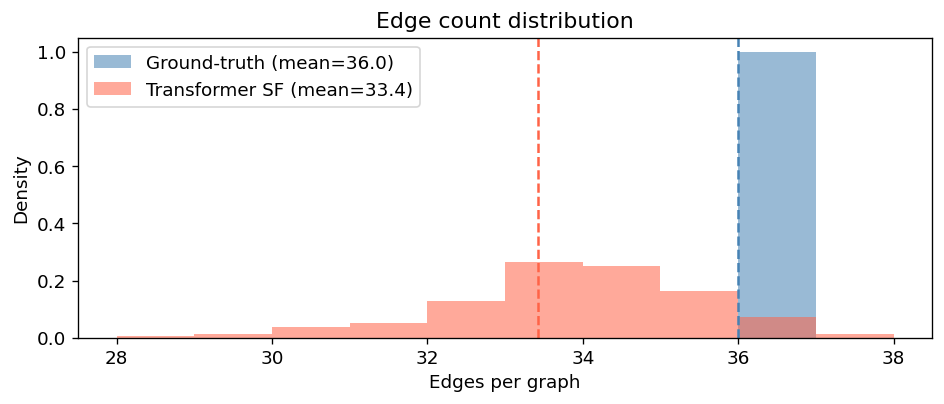

[Transformer SF]  KS=0.9143  p=0.0000


In [49]:
gt_edges = [g.number_of_edges() for g in test_gt_bin]
all_counts = [gt_edges] + [[g.number_of_edges() for g in gs] for gs in experiments.values()]
all_bins = np.arange(min(min(c) for c in all_counts), max(max(c) for c in all_counts) + 2)

colors = ['steelblue', 'tomato', 'mediumseagreen', 'darkorange', 'mediumpurple']
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(gt_edges, bins=all_bins, alpha=0.55, color='steelblue',
        label=f'Ground-truth (mean={np.mean(gt_edges):.1f})', density=True)
for (label, gs), color in zip(experiments.items(), colors[1:]):
    ec = [g.number_of_edges() for g in gs]
    ax.hist(ec, bins=all_bins, alpha=0.55, color=color,
            label=f'{label} (mean={np.mean(ec):.1f})', density=True)
    ax.axvline(np.mean(ec), color=color, ls='--', lw=1.5)
ax.axvline(np.mean(gt_edges), color='steelblue', ls='--', lw=1.5)
ax.set_xlabel('Edges per graph'); ax.set_ylabel('Density')
ax.set_title('Edge count distribution'); ax.legend(); plt.tight_layout(); plt.show()

for label, gs in experiments.items():
    ec = [g.number_of_edges() for g in gs]
    ks, p = stats.ks_2samp(gt_edges, ec)
    print(f'[{label}]  KS={ks:.4f}  p={p:.4f}')


## 5 · In-degree and out-degree distributions

[Transformer SF] In-degree distribution: KS=0.127 p=0.000
[Transformer SF] Out-degree distribution: KS=0.119 p=0.000


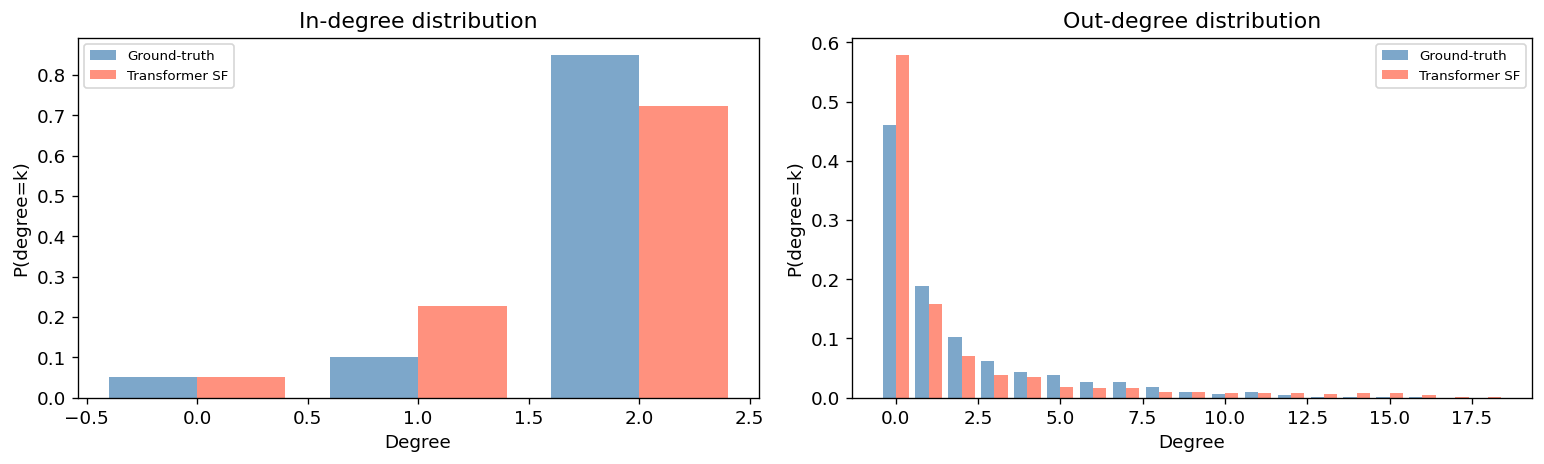

In [50]:
def degree_pmf(degrees, max_deg=None):
    c = Counter(degrees)
    max_deg = max_deg or max(c)
    xs = np.arange(max_deg + 1)
    ys = np.array([c.get(x, 0) for x in xs], dtype=float)
    ys /= ys.sum()
    return xs, ys

colors = ['steelblue', 'tomato', 'mediumseagreen', 'darkorange', 'mediumpurple']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, deg_fn, title in zip(axes, [indegrees, outdegrees],
                             ['In-degree distribution', 'Out-degree distribution']):
    gt_degs = deg_fn(test_gt_bin)
    all_degs = [gt_degs] + [deg_fn(gs) for gs in experiments.values()]
    max_deg  = max(max(d) for d in all_degs)
    n_exp    = len(experiments)
    w = 0.8 / (n_exp + 1)
    xs_gt, ys_gt = degree_pmf(gt_degs, max_deg)
    ax.bar(xs_gt - n_exp*w/2, ys_gt, width=w, alpha=0.7,
           color='steelblue', label='Ground-truth')
    for i, (label, gs) in enumerate(experiments.items()):
        gen_degs = deg_fn(gs)
        _, ys_gen = degree_pmf(gen_degs, max_deg)
        ax.bar(xs_gt + (i - n_exp//2 + 0.5)*w, ys_gen, width=w, alpha=0.7,
               color=colors[i+1], label=label)
        ks, p = stats.ks_2samp(gt_degs, gen_degs)
        print(f'[{label}] {title}: KS={ks:.3f} p={p:.3f}')
    ax.set_xlabel('Degree'); ax.set_ylabel('P(degree=k)')
    ax.set_title(title); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()


## 6 · Edge weight distribution

Ground-truth graphs carry continuous weights; generated graphs are binarized at the quantization threshold. We show both the GT weight histogram and the fraction of GT edges that survive binarization.

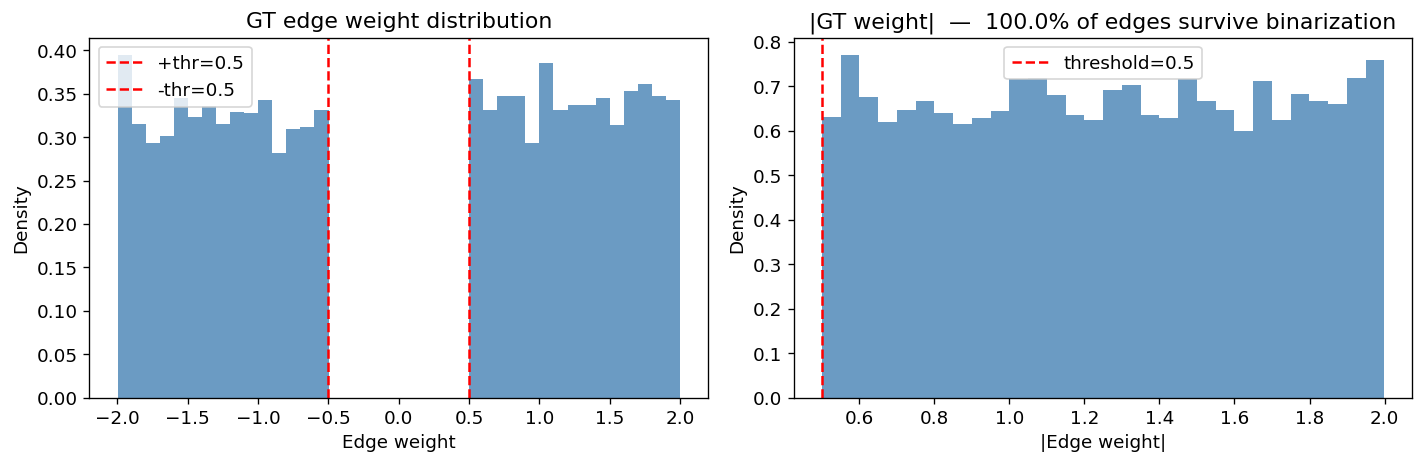

GT  weight range : [-1.999, 1.999]
GT  weight mean  : 0.0304  std: 1.3280
Fraction |w|>0.5: 1.000


In [51]:
gt_weights = np.array(edge_weights(test_gt))  # raw continuous weights

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ── left: full weight histogram ──────────────────────────────────────────────
ax = axes[0]
ax.hist(gt_weights, bins=40, color="steelblue", alpha=0.8, density=True)
ax.axvline( QUANTIZE_THR, color="red", ls="--", lw=1.5, label=f"+thr={QUANTIZE_THR}")
ax.axvline(-QUANTIZE_THR, color="red", ls="--", lw=1.5, label=f"-thr={QUANTIZE_THR}")
ax.set_xlabel("Edge weight")
ax.set_ylabel("Density")
ax.set_title("GT edge weight distribution")
ax.legend()

# ── right: absolute weight ────────────────────────────────────────────────────
ax = axes[1]
ax.hist(np.abs(gt_weights), bins=30, color="steelblue", alpha=0.8, density=True)
ax.axvline(QUANTIZE_THR, color="red", ls="--", lw=1.5, label=f"threshold={QUANTIZE_THR}")
kept = (np.abs(gt_weights) > QUANTIZE_THR).mean()
ax.set_xlabel("|Edge weight|")
ax.set_ylabel("Density")
ax.set_title(f"|GT weight|  —  {kept*100:.1f}% of edges survive binarization")
ax.legend()

plt.tight_layout()
plt.show()

print(f"GT  weight range : [{gt_weights.min():.3f}, {gt_weights.max():.3f}]")
print(f"GT  weight mean  : {gt_weights.mean():.4f}  std: {gt_weights.std():.4f}")
print(f"Fraction |w|>{QUANTIZE_THR}: {kept:.3f}")

## 7 · Per-node in/out-degree heatmaps

Shows the empirical distribution of (in-degree, out-degree) joint counts per node across all graphs — a compact summary of the directed structure.

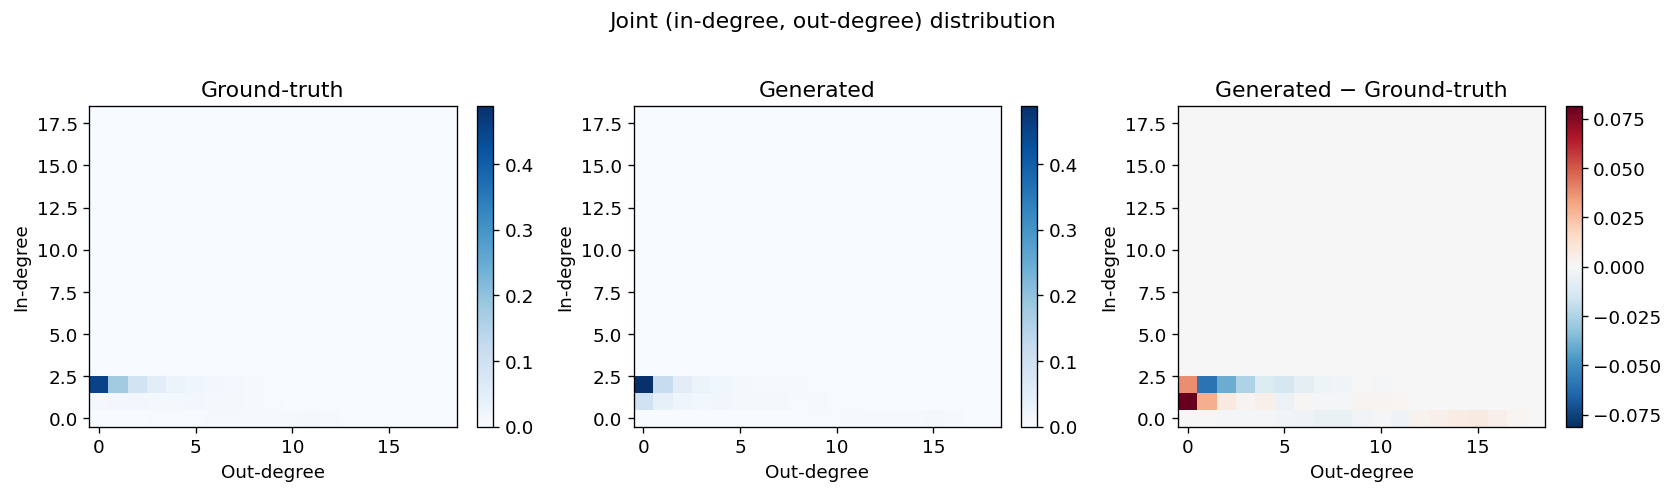

In [52]:
def joint_degree_matrix(graphs, max_deg=None):
    pairs = [(ind, outd)
             for g in graphs
             for (_, ind), (_, outd) in zip(g.in_degree(), g.out_degree())]
    if max_deg is None:
        max_deg = max(max(p) for p in pairs)
    M = np.zeros((max_deg + 1, max_deg + 1))
    for ind, outd in pairs:
        if ind <= max_deg and outd <= max_deg:
            M[ind, outd] += 1
    M /= M.sum()
    return M

max_deg = max(
    max(d for g in test_gt_bin for _, d in g.in_degree()),
    max(d for g in test_gt_bin for _, d in g.out_degree()),
    max(d for g in gen_graphs  for _, d in g.in_degree()),
    max(d for g in gen_graphs  for _, d in g.out_degree()),
)

M_gt  = joint_degree_matrix(test_gt_bin, max_deg)
M_gen = joint_degree_matrix(gen_graphs,  max_deg)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
vmax = max(M_gt.max(), M_gen.max())

for ax, M, title in zip(axes[:2],
                         [M_gt, M_gen],
                         ["Ground-truth", "Generated"]):
    im = ax.imshow(M, origin="lower", aspect="auto", vmin=0, vmax=vmax, cmap="Blues")
    ax.set_xlabel("Out-degree")
    ax.set_ylabel("In-degree")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)

# ── difference map ───────────────────────────────────────────────────────────
diff = M_gen - M_gt
lim  = np.abs(diff).max()
im = axes[2].imshow(diff, origin="lower", aspect="auto",
                    vmin=-lim, vmax=lim, cmap="RdBu_r")
axes[2].set_xlabel("Out-degree")
axes[2].set_ylabel("In-degree")
axes[2].set_title("Generated − Ground-truth")
plt.colorbar(im, ax=axes[2], fraction=0.046)

plt.suptitle("Joint (in-degree, out-degree) distribution", y=1.02)
plt.tight_layout()
plt.show()

## 8 · Visual comparison — example graphs

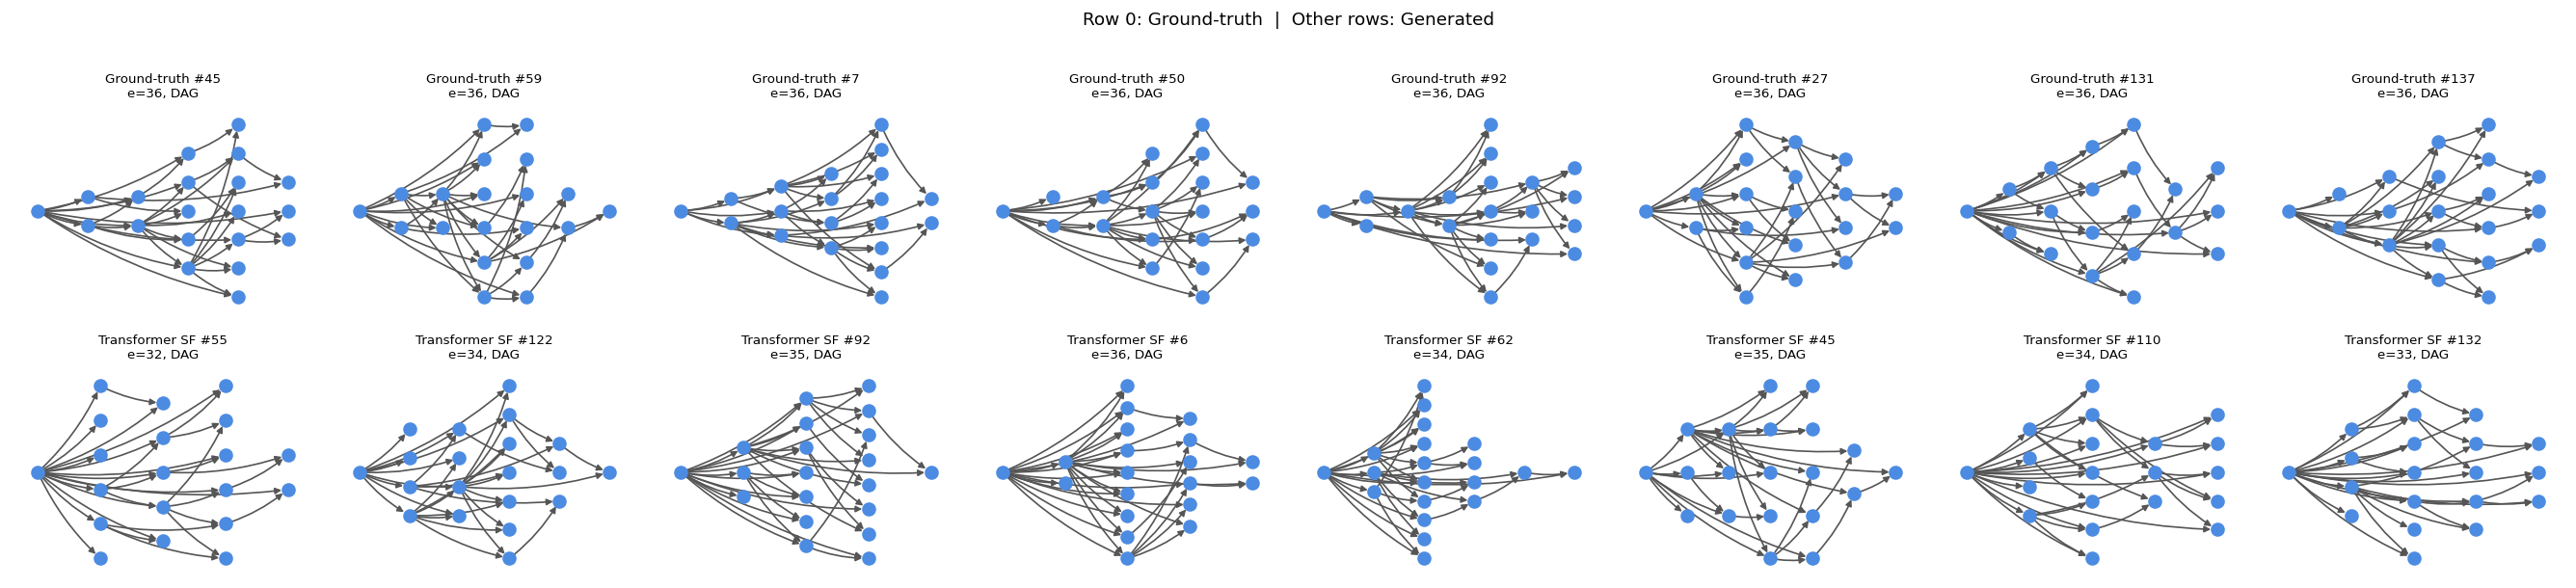

In [53]:
N_SHOW = 8

def draw_row(axes, graphs, label, indices=None):
    indices = indices or list(range(len(axes)))
    for ax, idx in zip(axes, indices):
        G = nx.DiGraph(graphs[idx])
        G.remove_edges_from(nx.selfloop_edges(G))
        try:
            if nx.is_directed_acyclic_graph(G):
                layers = {}
                for node in nx.topological_sort(G):
                    preds = list(G.predecessors(node))
                    layers[node] = max((layers[p] for p in preds), default=-1) + 1
                pos = {}; lc = Counter(layers.values()); lp = Counter()
                for node in nx.topological_sort(G):
                    l = layers[node]; cnt = lc[l]
                    pos[node] = (l, lp[l] - cnt/2); lp[l] += 1
            else:
                pos = nx.spring_layout(G, seed=0)
        except Exception:
            pos = nx.spring_layout(G, seed=0)
        nx.draw(G, pos=pos, ax=ax, with_labels=False, node_size=60,
                node_color='#4C8BE2', edge_color='#555555', width=1.0,
                arrows=True, arrowsize=8, connectionstyle='arc3,rad=0.1')
        dag_str = 'DAG' if nx.is_directed_acyclic_graph(G) else 'cycle!'
        ax.set_title(f'{label} #{idx}\ne={G.number_of_edges()}, {dag_str}', fontsize=8)
        ax.axis('off')

np.random.seed(0)
n_rows = 1 + len(experiments)
fig, axes = plt.subplots(n_rows, N_SHOW, figsize=(N_SHOW*2.8, n_rows*2.5))
if n_rows == 1: axes = [axes]

idx_gt = np.random.choice(len(test_gt_bin), N_SHOW, replace=False).tolist()
draw_row(axes[0], test_gt_bin, 'Ground-truth', idx_gt)
for row, (label, gs) in enumerate(experiments.items(), start=1):
    idx_gen = np.random.choice(len(gs), N_SHOW, replace=False).tolist()
    draw_row(axes[row], gs, label, idx_gen)

plt.suptitle('Row 0: Ground-truth  |  Other rows: Generated', fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig('/home/nicolas/GDSS/dag-pnp/gdss/samples/generated_dags_comparison.pdf', dpi=300)


## 9 · Summary scorecard

In [ ]:
from scipy.stats import wasserstein_distance

def tv_distance(p, q):
    n = max(len(p), len(q))
    p = np.pad(p, (0, n-len(p))); q = np.pad(q, (0, n-len(q)))
    return 0.5 * np.sum(np.abs(p - q))

gt_in  = indegrees(test_gt_bin)
gt_out = outdegrees(test_gt_bin)
gt_ec  = [g.number_of_edges() for g in test_gt_bin]

col_w = [28] + [26]*len(experiments)
header = f'{"Metric":<{col_w[0]}}' + ''.join(f'{lb:<{w}}' for lb, w in zip(experiments, col_w[1:]))
print(header)
print('─' * sum(col_w))

for metric, gt_vals, gen_fn in [
        ('DAG validity (%)',
         None,
         lambda gs: f'{100*sum(nx.is_directed_acyclic_graph(g) for g in gs)/len(gs):.1f}'),
        ('Mean edges',
         gt_ec,
         lambda gs: f'{np.mean([g.number_of_edges() for g in gs]):.1f} ± '
                    f'{np.std([g.number_of_edges() for g in gs]):.1f}'),
        ('Mean density',
         None,
         lambda gs: f'{np.mean([g.number_of_edges()/(g.number_of_nodes()*(g.number_of_nodes()-1)) for g in gs]):.4f}'),
        ('In-degree KS',
         gt_in,
         lambda gs: f'{stats.ks_2samp(gt_in, indegrees(gs))[0]:.4f}'),
        ('Out-degree KS',
         gt_out,
         lambda gs: f'{stats.ks_2samp(gt_out, outdegrees(gs))[0]:.4f}'),
        ('In-degree TV',
         None,
         lambda gs: (lambda g, r: f'{tv_distance(*r):.4f}')(
             gs, (degree_pmf(gt_in, max(max(gt_in), max(indegrees(gs))))[1],
                  degree_pmf(indegrees(gs), max(max(gt_in), max(indegrees(gs))))[1]))),
        ('Out-degree TV',
         None,
         lambda gs: (lambda g, r: f'{tv_distance(*r):.4f}')(
             gs, (degree_pmf(gt_out, max(max(gt_out), max(outdegrees(gs))))[1],
                  degree_pmf(outdegrees(gs), max(max(gt_out), max(outdegrees(gs))))[1]))),
        ('Edge-count Wass.',
         gt_ec,
         lambda gs: f'{wasserstein_distance(gt_ec, [g.number_of_edges() for g in gs]):.4f}'),
]:
    row = f'{metric:<{col_w[0]}}'
    for label, gs in experiments.items():
        row += f'{gen_fn(gs):<{col_w[1]}}'
    print(row)
